# 21 · 非线性、特征交叉与树容量

第18章保留总览；本章单独深入一个问题。正式200k实验不覆盖，教学训练使用独立共享记录。

## 先预测：加性模型在哪里失败？

线性logit只能表达特征的加性关系。交叉项把“两个字段共同出现”的状态加入设计矩阵；树通过条件路径表达交互。交叉能够增加表达力，也可能增加样本需求与过拟合，不能因为真实任务叫CTR就认定深模型一定更好。

先用明确构造的XOR数据检查表达能力，再用真实40k曝光只改变树叶数7→15。两部分分别是机制与真实训练，不能混成一个benchmark。

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'reclab').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from reclab.ads import latest, load_data, split_groups, NUM, CAT, FEATURES
from reclab.paths import ARTIFACTS
from reclab.probability import evaluate
preview=ARTIFACTS/'notebook-previews';preview.mkdir(parents=True,exist_ok=True)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
rng=np.random.default_rng(42)
x=rng.integers(0,2,size=(4000,2));y=(x[:,0]!=x[:,1]).astype(int)
print('Constructed XOR X:',x.shape,'y:',y.shape)
plain=LogisticRegression(C=10).fit(x[:3000],y[:3000])
cross=make_pipeline(PolynomialFeatures(degree=2,interaction_only=True,include_bias=False),LogisticRegression(C=10)).fit(x[:3000],y[:3000])
for name,model in [('additive',plain),('one_interaction',cross)]:
 r=evaluate(y[3000:],model.predict_proba(x[3000:])[:,1]);print(name,{k:r[k] for k in ['auc','logloss']})

Constructed XOR X: (4000, 2) y: (4000,)
additive {'auc': 0.5427435387673956, 'logloss': 0.6928292897764964}
one_interaction {'auc': 1.0, 'logloss': 0.004364692561560054}


## 交叉的形状与可识别边界

两个输入在interaction_only模式下得到[x1,x2,x1*x2]。这并非完整DeepFM或DCNv2复现，而是检验交互为什么可能有效。若增加字段数d，二阶成对交叉数为d(d−1)/2；匿名高基数onehot的全部交叉很容易超过本机预算。

先预测新增列在四种输入组合上的取值，执行穷举核对。再想想真实数据中一个罕见交叉只有一两条正例时会发生什么。

In [2]:
grid=np.array([[0,0],[0,1],[1,0],[1,1]])
transformed=cross[0].transform(grid)
display(pd.DataFrame(transformed,columns=['x1','x2','x1*x2']))
assert transformed.shape==(4,3)
assert np.array_equal(transformed[:,2],grid[:,0]*grid[:,1])
print('All second-order interactions for d=39:',39*38//2)

,x1,x2,x1*x2
0,0.0,0.0,0.0
1,0.0,1.0,0.0
2,1.0,0.0,0.0
3,1.0,1.0,1.0


All second-order interactions for d=39: 741


## 真实训练：只改变树叶数

固定原始数值、训练top255类别、80棵树、学习率.05、最小叶样本100与L2=1；只改变num_leaves。类别用类别分裂，不能把编码整数直接当有序数。预算较原正式200k更小，所以结果只在本章两组之间比较。

注意树深和叶数不是同一概念；15叶不会保证每条路径深4。训练与评估同样走共享registry，读取select而不是audit。

Shared workshop: 20261030T130911-14b5a3de {'raw': [40000, 39], 'train': 22024, 'select': 6006}


,method,fit_seconds,auc,logloss,brier,ece
0,leaves_7,0.126307,0.704286,0.134063,0.030587,0.003655
1,leaves_15,0.175748,0.688730,0.137054,0.030825,0.007551


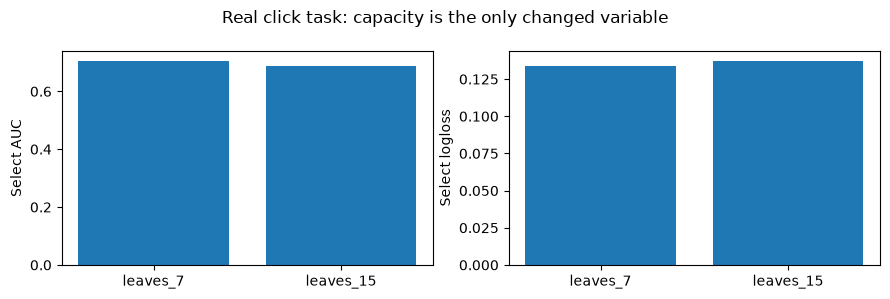

In [3]:
from reclab.ads_teaching import workshop
run_id,comparison=workshop('tree_capacity')
print('Shared workshop:',run_id,comparison['shapes'])
table=pd.DataFrame([{'method':r['method'],'fit_seconds':r['fit_seconds'],**{k:r['select'][k] for k in ['auc','logloss','brier','ece']}} for r in comparison['rows']])
display(table)
fig,axes=plt.subplots(1,2,figsize=(9,3));axes[0].bar(table.method,table.auc);axes[1].bar(table.method,table.logloss)
axes[0].set(ylabel='Select AUC');axes[1].set(ylabel='Select logloss');fig.suptitle('Real click task: capacity is the only changed variable');fig.tight_layout();fig.savefig(preview/'21_trees.png',dpi=130);plt.show()

## 用损失而不是复杂度解释结果

本章叶数对照只回答这段数据中的容量变化，不能拿它和20章不同模型的运行时间作严格架构benchmark。正式200k实验中线性模型优于两个树候选，160棵树也没有胜过80棵；这个负结果保留。

下面读取正式实验聚合，只用于理解“复杂不保证更好”，不要据此重新调当前模型并继续使用相同audit宣称提升。

In [4]:
formal_receipt,formal=latest()
display(pd.DataFrame([{'method':r['method'],'audit_auc':r['audit']['auc'],'audit_logloss':r['audit']['logloss']} for r in formal['rows'] if r['method'] in ['linear_onehot','gbdt_80','gbdt_160']]))
print('Formal run unchanged:',formal_receipt['run_id'])
print('Workshop select and formal audit have different sample/fit budgets; no mixed leaderboard.')

,method,audit_auc,audit_logloss
0,linear_onehot,0.721468,0.135423
1,gbdt_80,0.706329,0.136029
2,gbdt_160,0.703035,0.137404


Formal run unchanged: 20261030T125738-f82b6582
Workshop select and formal audit have different sample/fit budgets; no mixed leaderboard.


## 练习：交叉不是万能的

只把构造标签从XOR改成x1，其他输入、训练预算不变，再比较有无交叉。如果目标本来是加性的，额外交叉未必有帮助。这里标签是构造的机制输入，绝不是对真实点击标签进行篡改。

解释时分别写下表达能力、统计误差和优化预算三种可能性。若想探索真实类别交叉，应先在train上限制词表，使用新select协议，并预留新的最终审计。

In [5]:
target=x[:,0].copy()  # Only the synthetic target mechanism changed.
for name,model in [('additive',LogisticRegression(C=10)),('interaction',make_pipeline(PolynomialFeatures(2,interaction_only=True,include_bias=False),LogisticRegression(C=10)))]:
 model.fit(x[:3000],target[:3000]);r=evaluate(target[3000:],model.predict_proba(x[3000:])[:,1]);print(name,r['auc'],r['logloss'])

additive 1.0 0.0009870029880096182
interaction 1.0 0.0009621421929528383
